## **Exercise: Preprocessing**

1. Data
1. EDA
1. Missing value & Outliers Exploration
1. Data Splitting
1. Preprocessing
    - Binning 
    - Impute missing values
    - Encoding
    - Polynomial
1. Model fitting and evaluation
1. Model properties

**Data**

An individual’s annual income results from various factors. 
Intuitively, it is influenced by the individual’s education level, age, gender, occupation, and etc.
<br>

Fields:
<br>
The dataset contains 16 columns
<br>
Target filed: Income
<br>
- The income is divide into two classes: <=50K % >50K
<br>
Number of attributes: 14
<br>
- These are the demographics and other 
<br>
features to describe a person

<br>
drop columns: 'fnlwgt', 'education'

We will explore the possibility in predicting income level based on the individual’s personal information.


In [1]:
# !pip install category_encoders

In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, KBinsDiscretizer
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
import category_encoders as ce

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

In [3]:
df_adult = pd.read_csv('adult.csv')
df_adult.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [4]:
# df_adult['capital.gain'].value_counts()

In [5]:
df_adult['income'] = np.where(df_adult['income']=='>50K',1,0)

In [6]:
df_adult.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week,income
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456,0.240810
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429,0.427581
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000,0.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000,0.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000,0.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000,0.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000,1.000000


In [7]:
df_adult.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  32561 non-null  object
 14  income          32561 non-null  int64 
dtypes: int64(7), object(8)
memory usage: 3.7+ MB


## Missing Value

Missing value in this dataset marked with "?"

In [8]:
df_adult.replace('?', np.nan, inplace = True)

In [9]:
df_adult.isnull().sum()/df_adult.shape[0] * 100

age               0.000000
workclass         5.638647
fnlwgt            0.000000
education         0.000000
education.num     0.000000
marital.status    0.000000
occupation        5.660146
relationship      0.000000
race              0.000000
sex               0.000000
capital.gain      0.000000
capital.loss      0.000000
hours.per.week    0.000000
native.country    1.790486
income            0.000000
dtype: float64

<Axes: >

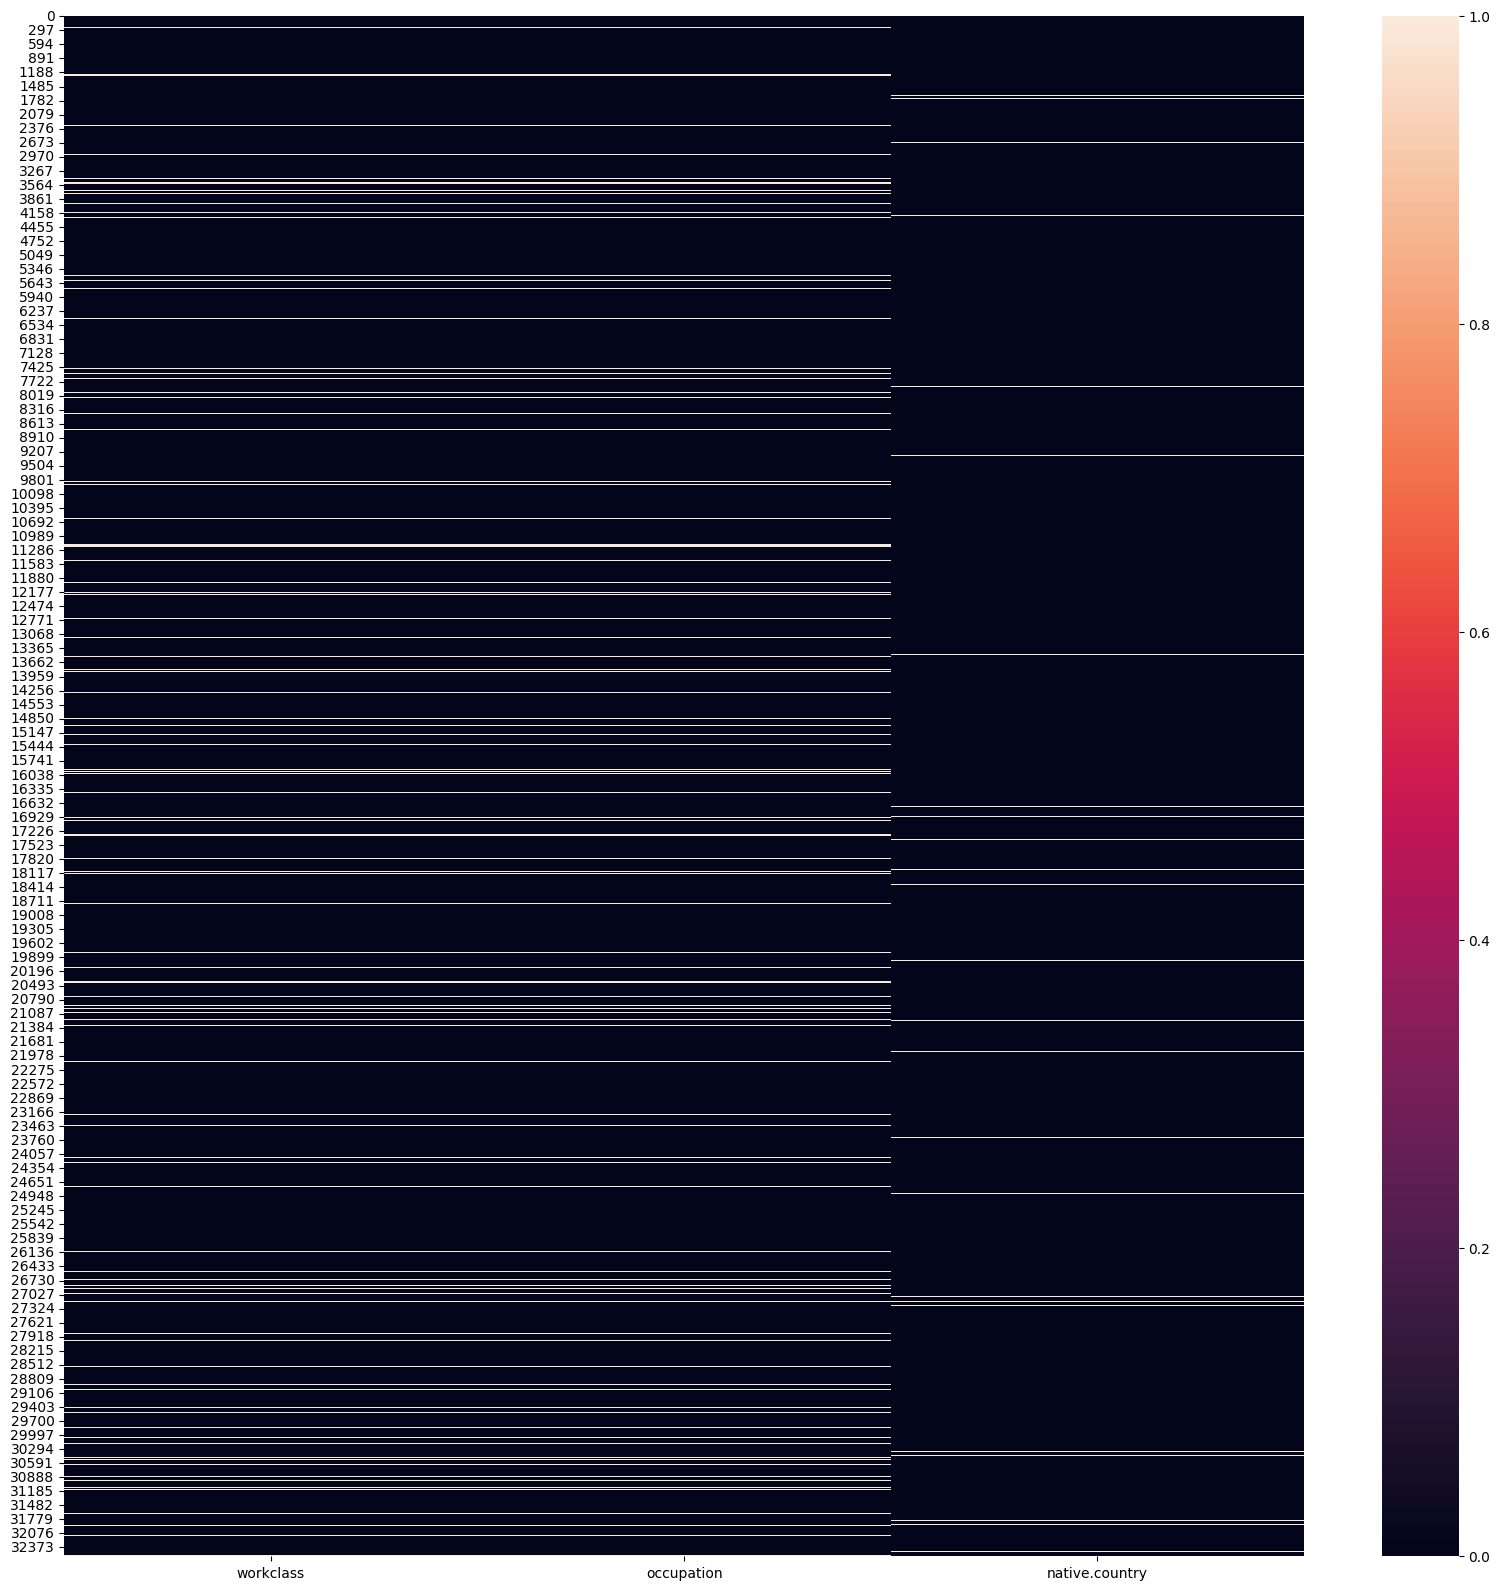

In [10]:
plt.figure(figsize = (20,20))
sns.heatmap(df_adult[['workclass','occupation','native.country']].isnull())

<Axes: >

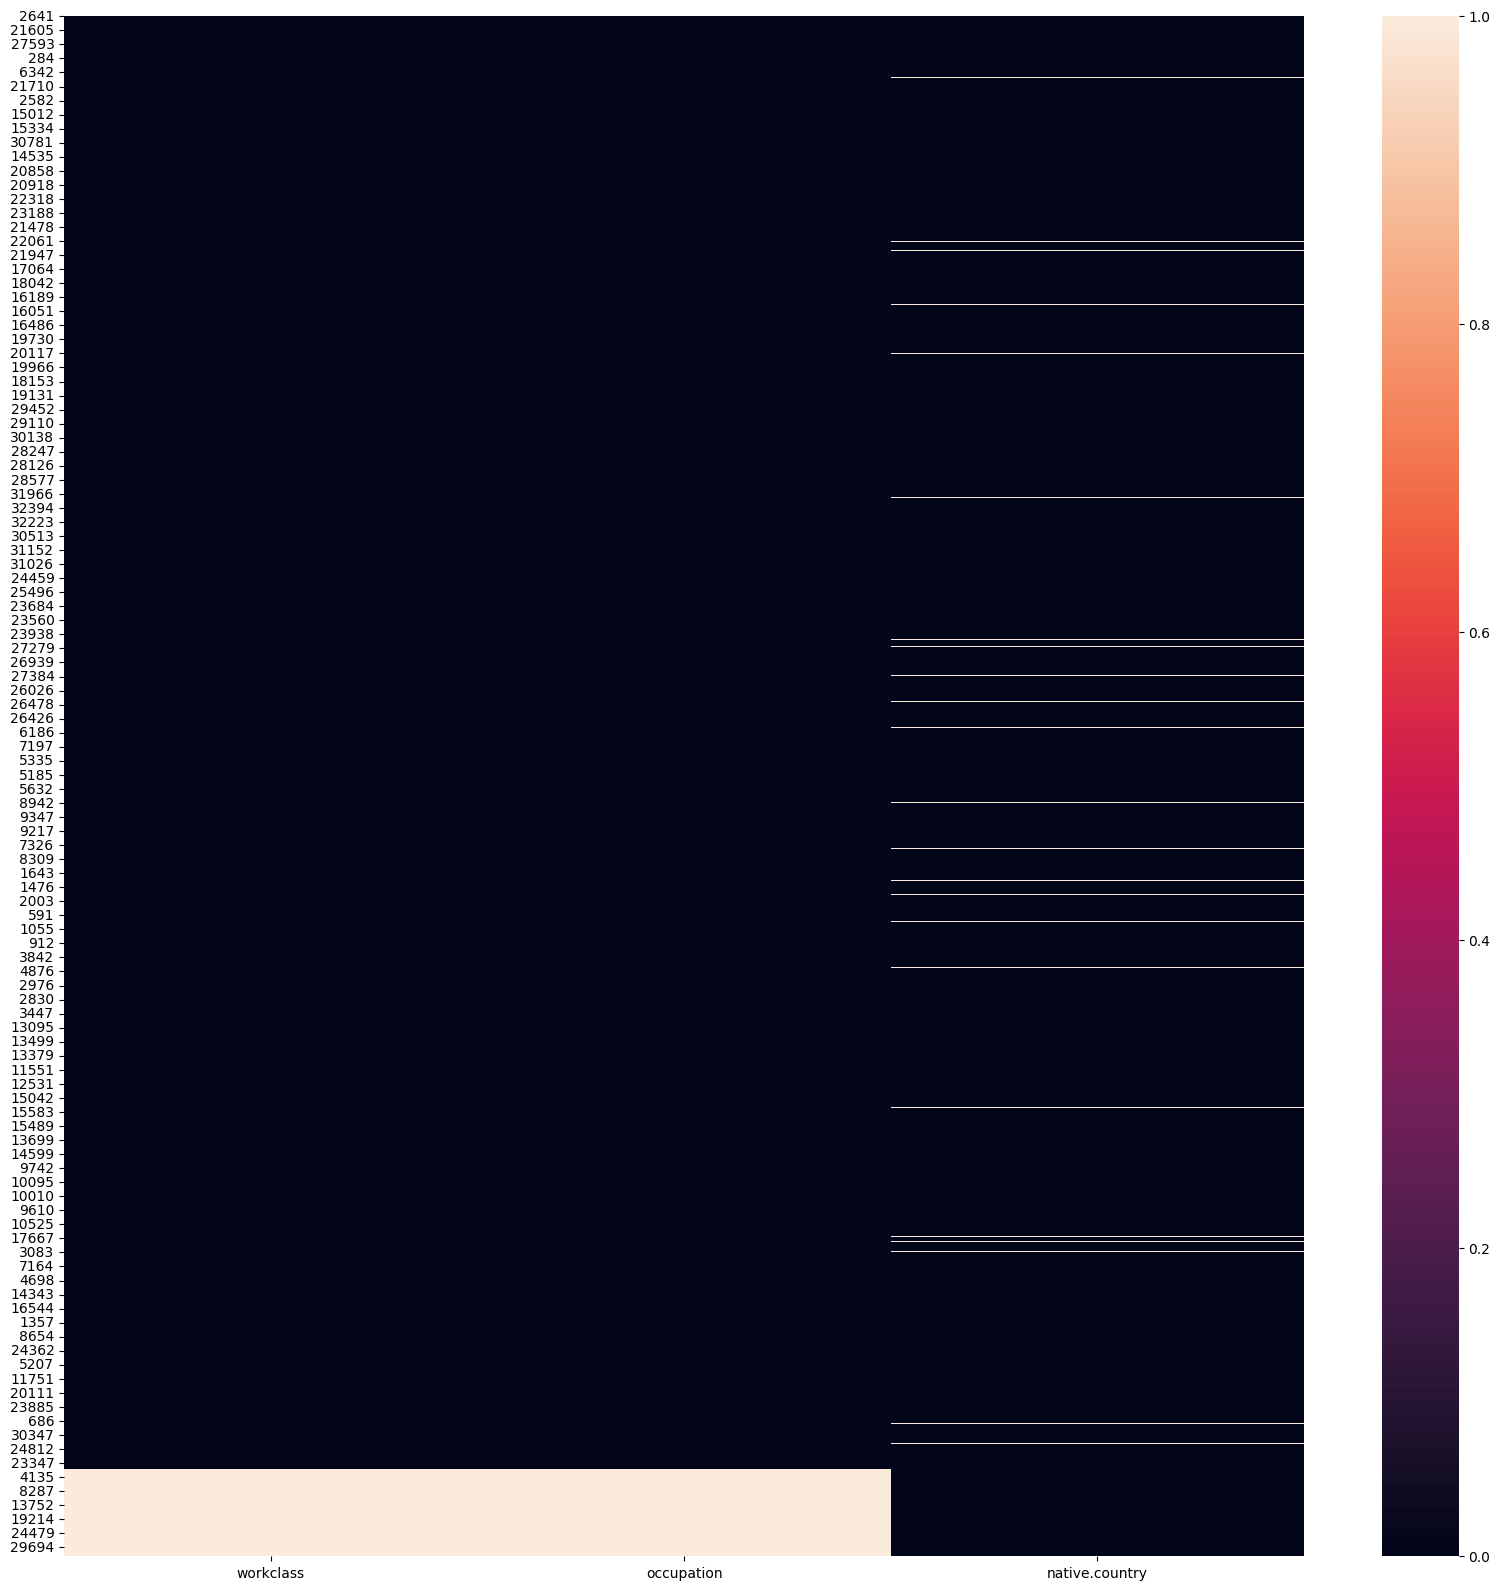

In [11]:
plt.figure(figsize = (20,20))
sns.heatmap(df_adult[['workclass','occupation','native.country']].sort_values('workclass').isnull())

The Missing Variable:
1. workclass
1. occupation
1. native.country

## Duplicates

In [12]:
df_adult.duplicated().sum()

24

In [13]:
df_adult = df_adult.drop_duplicates()
df_adult.shape

(32537, 15)

## Outliers

In [14]:
# Numerical Features
num_feature = [fea for fea in df_adult.describe().columns][:-1]
num_feature

['age',
 'fnlwgt',
 'education.num',
 'capital.gain',
 'capital.loss',
 'hours.per.week']

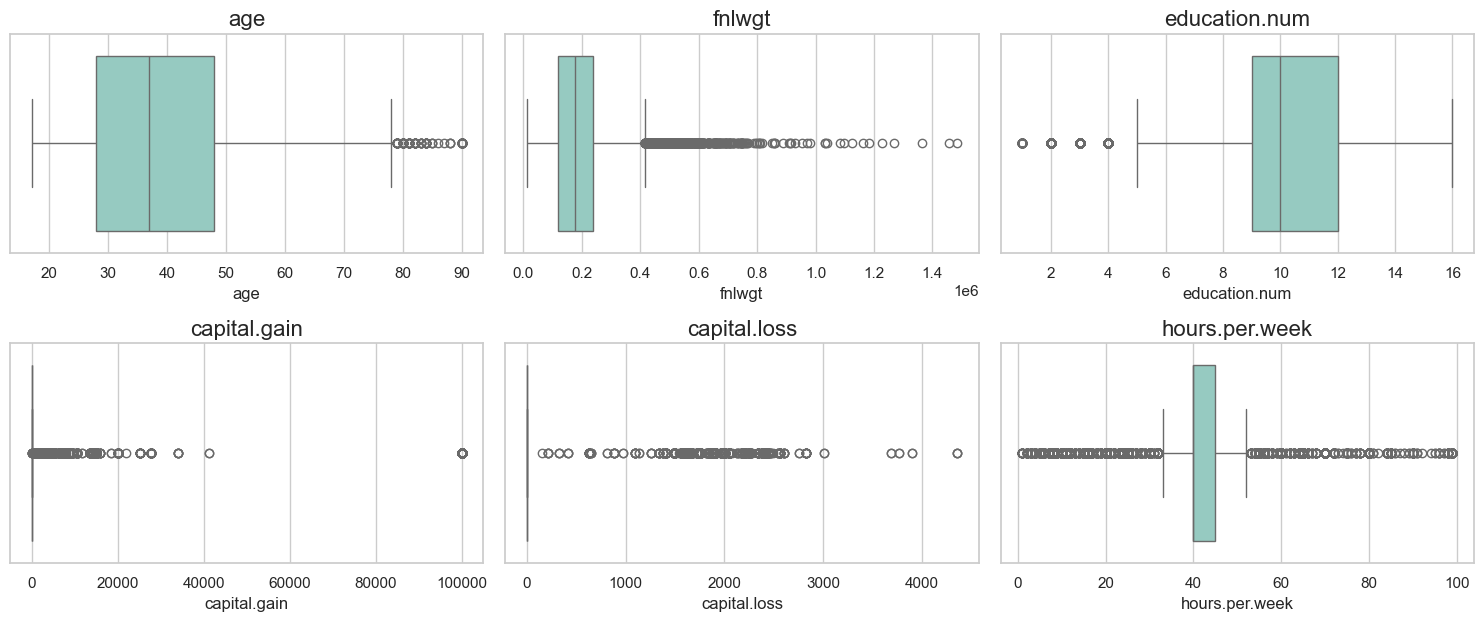

In [15]:
plt.figure(figsize=(15, 9), facecolor='white')
sns.set(style='whitegrid', palette='Set3')
plotnumber = 1
    
for feature in num_feature:
    ax = plt.subplot(3,3, plotnumber)
    sns.boxplot(x=feature, data=df_adult);
    plt.title(feature, fontsize=16)
    plt.tight_layout()
    plotnumber = plotnumber + 1

In [16]:
# RobustScaler().fit_transform(df_adult[['income']])

In [17]:
df_adult.shape

(32537, 15)

In [18]:
df_adult = df_adult[df_adult['education.num'] >= 4]
df_adult.shape

(31989, 15)

In [19]:
# hapus outliers kolom 'capital.gain'
df_adult = df_adult[df_adult['capital.gain'] < 20000]
df_adult.shape

(31737, 15)

In [20]:
# hapus outliers kolom 'capital.loss'
df_adult = df_adult[df_adult['capital.loss'] < 3000]
df_adult.shape

(31726, 15)

In [21]:
# hapus outliers kolom 'hours.per.week'
df_adult = df_adult[~((df_adult['hours.per.week'] < 10) | (df_adult['hours.per.week'] > 80))]
df_adult.shape

(31071, 15)

In [22]:
# df_adult.groupby('education.num')['workclass'].apply(lambda x: x.mode()[0])

## Data Splitting

In [23]:
# define fetures and target
X = df_adult.drop(columns = ['fnlwgt','income','education'])
y = df_adult['income']

In [24]:
# data splitting
X_train, X_test, y_train, y_test = train_test_split(X,y, stratify=y, random_state=10, test_size=0.2)

## Preprocessing

In [25]:
X.head()

,age,workclass,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country
11,38,Self-emp-not-inc,15,Never-married,Prof-specialty,Not-in-family,White,Male,0,2824,45,United-States
12,52,Private,13,Widowed,Other-service,Not-in-family,White,Female,0,2824,20,United-States
13,32,Private,14,Separated,Exec-managerial,Not-in-family,White,Male,0,2824,55,United-States
14,51,NaN,16,Never-married,NaN,Not-in-family,White,Male,0,2824,40,United-States
15,46,Private,15,Divorced,Prof-specialty,Not-in-family,White,Male,0,2824,40,United-States


In [26]:
X.describe()

,age,education.num,capital.gain,capital.loss,hours.per.week
count,31071.000000,31071.000000,31071.000000,31071.000000,31071.000000
mean,38.244891,10.195616,531.724534,87.430369,40.577259
std,13.332677,2.371873,2209.316271,399.715215,10.930330
min,17.000000,4.000000,0.000000,0.000000,10.000000
25%,28.000000,9.000000,0.000000,0.000000,40.000000
50%,37.000000,10.000000,0.000000,0.000000,40.000000
75%,47.000000,12.000000,0.000000,0.000000,45.000000
max,90.000000,16.000000,18481.000000,2824.000000,80.000000


### Encoding, Impute Missing Values, and Binning

Preprocess scheme:
1. one hot encoding : relationship, race, sex
1. binary encoding : workclass, marital status, occupation, native country  
1. no treatment : size

Impute missing values with 'others':
- workclass, 'occupation','native.country' 

In [27]:
df_adult.describe(include='object') 

,workclass,education,marital.status,occupation,relationship,race,sex,native.country
count,29466,31071,31071,29460,31071,31071,31071,30530
unique,8,13,7,14,6,5,2,41
top,Private,HS-grad,Married-civ-spouse,Craft-repair,Husband,White,Male,United-States
freq,21804,10268,14226,3978,12551,26537,20767,28160


In [28]:
# pipeline untuk kolom-kolom binary encoder
imp_binary = Pipeline([
    ('imputer', SimpleImputer(strategy = 'constant', fill_value = 'others')),
    ('binary encoder', ce.BinaryEncoder())
])

transformer = ColumnTransformer([
    ('bin_ordinal', KBinsDiscretizer(n_bins=7, encode='ordinal', strategy='uniform'), ['age']),
    ('one hot encoder', OneHotEncoder(), ['relationship','race','sex']),
    ('binary encoder', imp_binary, ['workclass','marital.status','occupation','native.country']),
], remainder = 'passthrough')
transformer

ColumnTransformer(remainder='passthrough',
                  transformers=[('bin_ordinal',
                                 KBinsDiscretizer(encode='ordinal', n_bins=7,
                                                  strategy='uniform'),
                                 ['age']),
                                ('one hot encoder', OneHotEncoder(),
                                 ['relationship', 'race', 'sex']),
                                ('binary encoder',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(fill_value='others',
                                                                strategy='constant')),
                                                 ('binary encoder',
                                                  BinaryEncoder())]),
                                 ['workclass', 'marital.status', 'occupation',
                                  'native.country'])])

In [29]:
# Column Transformer
X_train_prep = transformer.fit_transform(X_train)
X_test_prep = transformer.transform(X_test)

X_train_prep = pd.DataFrame(X_train_prep)
X_test_prep = pd.DataFrame(X_test_prep)

X_train_prep.head()

,0,1,2,3,4,5,6,7,8,9,...,25,26,27,28,29,30,31,32,33,34
0,3.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,13.0,0.0,0.0,40.0
1,2.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,13.0,0.0,0.0,40.0
2,3.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,13.0,0.0,0.0,40.0
3,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,9.0,0.0,0.0,40.0
4,5.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,9.0,0.0,0.0,20.0


### Coba lihat Nama Kolom hasil Preprocessing

In [30]:
X_result_train = X_train_prep.copy()
X_result_train.head()

,0,1,2,3,4,5,6,7,8,9,...,25,26,27,28,29,30,31,32,33,34
0,3.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,13.0,0.0,0.0,40.0
1,2.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,13.0,0.0,0.0,40.0
2,3.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,13.0,0.0,0.0,40.0
3,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,9.0,0.0,0.0,40.0
4,5.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,9.0,0.0,0.0,20.0


In [31]:
X_result_test = X_test_prep.copy()
X_result_test.head()

,0,1,2,3,4,5,6,7,8,9,...,25,26,27,28,29,30,31,32,33,34
0,2.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,14.0,15024.0,0.0,50.0
1,2.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,11.0,0.0,0.0,32.0
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,9.0,0.0,0.0,40.0
3,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,9.0,0.0,2001.0,40.0
4,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,10.0,0.0,0.0,40.0


In [32]:
feat_binning = list(transformer.transformers_[0][1].feature_names_in_)
feat_binning 


['age']

In [33]:
feat_onehot = list(transformer.transformers_[1][1].get_feature_names_out())
# feat_onehot

In [34]:
feat_binary = list(transformer.transformers_[2][1]['binary encoder'].get_feature_names())
# feat_binary 

/Users/dikjaya/miniconda3/lib/python3.12/site-packages/category_encoders/utils.py:366: FutureWarning: `get_feature_names` is deprecated in all of sklearn. Use `get_feature_names_out` instead.
  warnings.warn("`get_feature_names` is deprecated in all of sklearn. Use `get_feature_names_out` instead.",


In [35]:
feat_numerical = list(X_train.columns[transformer.transformers_[3][2]])
# feat_numerical

/Users/dikjaya/miniconda3/lib/python3.12/site-packages/sklearn/compose/_column_transformer.py:1624: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


In [36]:
# len(features)

In [37]:
# menyatukan nama-nama kolom
features = feat_binning + feat_onehot + feat_binary + feat_numerical

X_train_prep.columns = features
X_test_prep.columns = features

X_train_prep

,age,relationship_Husband,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,race_Amer-Indian-Eskimo,race_Asian-Pac-Islander,race_Black,...,3_0,3_1,3_2,3_3,3_4,3_5,education.num,capital.gain,capital.loss,hours.per.week
0,3.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,13.0,0.0,0.0,40.0
1,2.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,13.0,0.0,0.0,40.0
2,3.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,13.0,0.0,0.0,40.0
3,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,9.0,0.0,0.0,40.0
4,5.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,9.0,0.0,0.0,20.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24851,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,9.0,0.0,0.0,40.0
24852,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,10.0,0.0,0.0,20.0
24853,4.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,9.0,0.0,0.0,40.0
24854,2.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,9.0,0.0,0.0,50.0


### Polynomial Features

In [38]:
# Polynomial Features
poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train_prep)
X_test_poly = poly.transform(X_test_prep)

# X_train_poly

In [39]:
X_train_poly = pd.DataFrame(X_train_poly)
X_test_poly = pd.DataFrame(X_test_poly)

X_test_poly

,0,1,2,3,4,5,6,7,8,9,...,656,657,658,659,660,661,662,663,664,665
0,1.0,2.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,196.0,210336.0,0.0,700.0,225720576.0,0.0,751200.0,0.0,0.0,2500.0
1,1.0,2.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,121.0,0.0,0.0,352.0,0.0,0.0,0.0,0.0,0.0,1024.0
2,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,81.0,0.0,0.0,360.0,0.0,0.0,0.0,0.0,0.0,1600.0
3,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,81.0,0.0,18009.0,360.0,0.0,0.0,0.0,4004001.0,80040.0,1600.0
4,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,100.0,0.0,0.0,400.0,0.0,0.0,0.0,0.0,0.0,1600.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6210,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,100.0,0.0,0.0,400.0,0.0,0.0,0.0,0.0,0.0,1600.0
6211,1.0,2.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,100.0,0.0,0.0,800.0,0.0,0.0,0.0,0.0,0.0,6400.0
6212,1.0,3.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,144.0,0.0,0.0,480.0,0.0,0.0,0.0,0.0,0.0,1600.0
6213,1.0,5.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,81.0,0.0,0.0,315.0,0.0,0.0,0.0,0.0,0.0,1225.0


In [40]:
X_train_poly.columns = poly.get_feature_names_out()
X_test_poly.columns = poly.get_feature_names_out()

X_train_poly.head()

,1,age,relationship_Husband,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,race_Amer-Indian-Eskimo,race_Asian-Pac-Islander,...,education.num^2,education.num capital.gain,education.num capital.loss,education.num hours.per.week,capital.gain^2,capital.gain capital.loss,capital.gain hours.per.week,capital.loss^2,capital.loss hours.per.week,hours.per.week^2
0,1.0,3.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,169.0,0.0,0.0,520.0,0.0,0.0,0.0,0.0,0.0,1600.0
1,1.0,2.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,169.0,0.0,0.0,520.0,0.0,0.0,0.0,0.0,0.0,1600.0
2,1.0,3.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,169.0,0.0,0.0,520.0,0.0,0.0,0.0,0.0,0.0,1600.0
3,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,81.0,0.0,0.0,360.0,0.0,0.0,0.0,0.0,0.0,1600.0
4,1.0,5.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,81.0,0.0,0.0,180.0,0.0,0.0,0.0,0.0,0.0,400.0


## Model Fitting and evaluation




Tanpa Polynomial Features

In [41]:
model = DecisionTreeClassifier(max_depth=3, random_state=10)
model.fit(X_train_prep, y_train)

y_pred = model.predict(X_test_prep)
print('accuracy:',accuracy_score(y_test, y_pred))

accuracy: 0.8337892196299276


Dengan Polynomial Features

In [42]:
model = DecisionTreeClassifier(max_depth=3, random_state=10)
model.fit(X_train_poly, y_train)

y_pred = model.predict(X_test_poly)
print('accuracy:',accuracy_score(y_test, y_pred))

accuracy: 0.8336283185840708


Polynomial features tidak meningkatkan performa model


## Model Properties

In [43]:
importance_table = pd.DataFrame({
    'imp':model.feature_importances_
}, index = X_train_poly.columns).sort_values('imp', ascending=False)

importance_table.head(10)

,imp
relationship_Husband education.num,0.582708
capital.gain,0.179975
1_1 education.num,0.111054
sex_Male education.num,0.067201
relationship_Husband capital.gain,0.035279
capital.gain^2,0.023163
age race_Black,0.000620
0_0 capital.gain,0.000000
0_1^2,0.000000
0_1 0_2,0.000000


<Axes: >

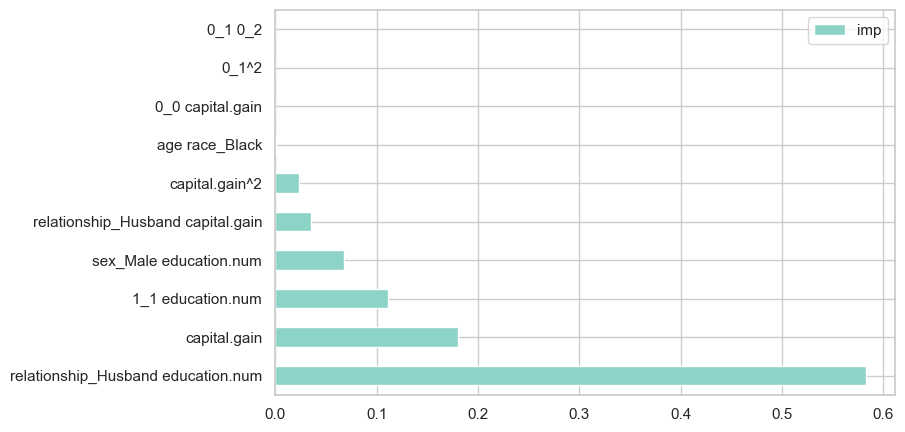

In [44]:
importance_table.head(10).plot(kind = 'barh', figsize = (8,5))

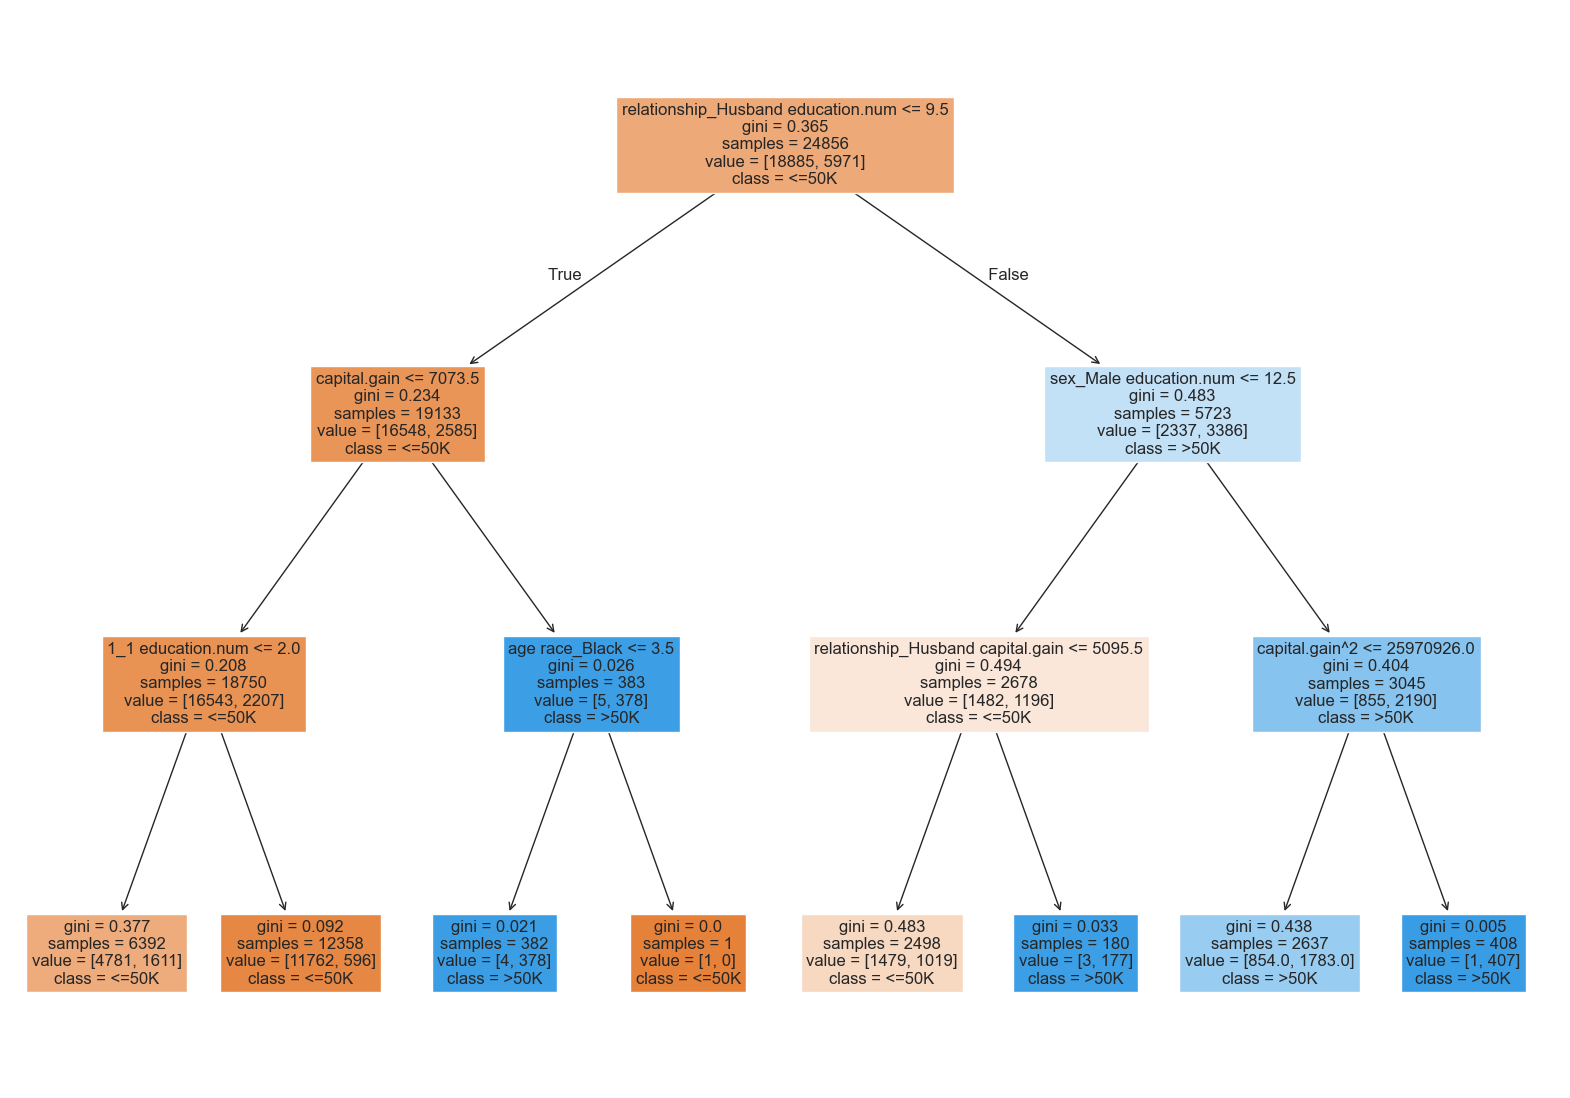

In [45]:
plt.figure(figsize = (20,14))
plot_tree(model, feature_names=X_train_poly.columns, filled = True, class_names = ['<=50K','>50K'], fontsize=12)
plt.show()